In [1]:
# ================================
# Project B: Customer Segmentation
# ================================

# Phase 1: Setup
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("C:/Users/krishna/Downloads/archive (5)/Mall_Customers.csv")
print(df.head())


   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [2]:
# Phase 2: Data Preparation
X = df[['Age','Annual Income (k$)','Spending Score (1-100)']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

C:\Users\krishna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\krishna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\krishna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\krishna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak o

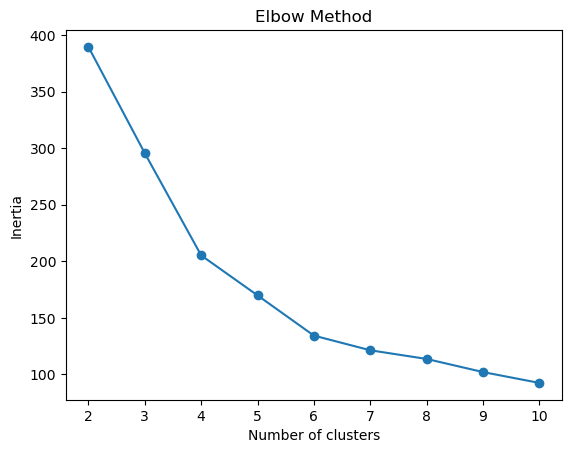

Silhouette Score: 0.40846873777345605


C:\Users\krishna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [3]:
# Phase 3: K-Means Clustering
import os
os.environ["OMP_NUM_THREADS"] = "1"

inertia = []
for k in range(2,11):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.plot(range(2,11), inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.show()

# Choose k=5 (example)
kmeans = KMeans(n_clusters=5, random_state=42)
labels = kmeans.fit_predict(X_scaled)
df['Cluster'] = labels

print("Silhouette Score:", silhouette_score(X_scaled, labels))


In [4]:
# Phase 4: Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=5)
hc_labels = hc.fit_predict(X_scaled)
df['HC_Cluster'] = hc_labels


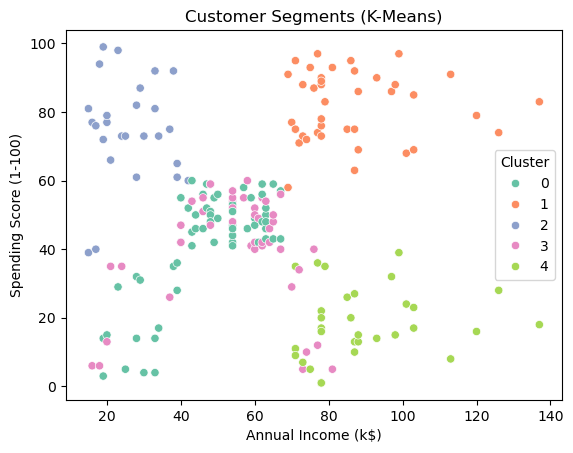

In [5]:
# Phase 5: Visualization
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', hue='Cluster', data=df, palette='Set2')
plt.title("Customer Segments (K-Means)")
plt.show()


In [6]:
# Phase 6: Insights
print(df.groupby('Cluster').mean(numeric_only=True))


         CustomerID        Age  Annual Income (k$)  Spending Score (1-100)  \
Cluster                                                                      
0         68.775862  55.275862           47.620690               41.706897   
1        161.025000  32.875000           86.100000               81.525000   
2         23.461538  25.769231           26.115385               74.846154   
3         86.377778  26.733333           54.311111               40.911111   
4        166.870968  44.387097           89.774194               18.483871   

         HC_Cluster  
Cluster              
0          1.689655  
1          1.950000  
2          0.307692  
3          0.533333  
4          2.806452  
